<a href="https://colab.research.google.com/github/nurfahdilla293/praktikum_evaluasi_model.ipynb/blob/main/Praktikum_Bab7_Evaluasi_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum ke - 7 Machine Learning
## Evaluasi Model: Confusion Matrix, Precision-Recall, ROC-AUC, dan Stratified K-Fold CV



## Praktikum 7.1 – Persiapan Library

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix,
    precision_score, recall_score, f1_score, roc_curve, auc,
    precision_recall_curve, classification_report)

## Praktikum 7.2 – Import Dataset
Dataset sintetis dengan 1000 sampel, 10 fitur, dan kelas tidak seimbang (70% : 30%).

In [2]:
X, y = make_classification(n_samples=1000, n_features=10,
                           weights=[0.7, 0.3], random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y,
                           test_size=0.3, random_state=42, stratify=y)
print("Ukuran X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Distribusi kelas y_test:", np.bincount(y_test))

Ukuran X_train: (700, 10) | X_test: (300, 10)
Distribusi kelas y_test: [209  91]


## Praktikum 7.3 – Preprocessing dan Training Model

In [3]:
model = LogisticRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

## Praktikum 7.4 – Evaluasi

In [4]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)
print("Precision :", round(precision_score(y_test, y_pred), 3))
print("Recall    :", round(recall_score(y_test, y_pred), 3))
print("F1-Score  :", round(f1_score(y_test, y_pred), 3))
print()
print(classification_report(y_test, y_pred))

# Stratified k-fold Cross-Validation untuk perbandingan model
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
skor_cv = cross_val_score(model, X, y, cv=skf, scoring="f1")
print("F1-Score tiap fold:", np.round(skor_cv, 3))
print("Rata-rata F1-Score:", round(skor_cv.mean(), 3), "+/-", round(skor_cv.std(), 3))

Confusion Matrix:
 [[193  16]
 [ 20  71]]
Precision : 0.816
Recall    : 0.78
F1-Score  : 0.798

              precision    recall  f1-score   support

           0       0.91      0.92      0.91       209
           1       0.82      0.78      0.80        91

    accuracy                           0.88       300
   macro avg       0.86      0.85      0.86       300
weighted avg       0.88      0.88      0.88       300

F1-Score tiap fold: [0.821 0.793 0.771 0.807 0.803]
Rata-rata F1-Score: 0.799 +/- 0.017


## Praktikum 7.5 – Visualisasi (ROC Curve)

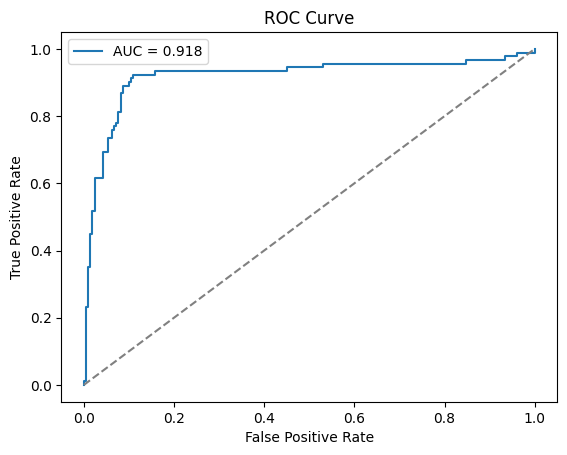

In [5]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], '--', color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend()
plt.show()

**Interpretasi:** Nilai AUC yang mendekati 1 menunjukkan model mampu membedakan kelas positif dan negatif dengan baik pada berbagai threshold. Nilai F1-Score yang stabil pada Stratified K-Fold CV menunjukkan performa model tidak bergantung pada satu pembagian data.

---
# Latihan Praktikum
Laporan Evaluasi Lengkap
Dataset: *breast cancer*. Model: Logistic Regression dan Decision Tree. Output: Confusion Matrix, Precision/Recall/F1, ROC curve, dan PR curve.

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score,
                             accuracy_score)

data = load_breast_cancer()
Xb, yb = data.data, data.target
print("Jumlah sampel:", Xb.shape, "| Distribusi kelas (0=malignant, 1=benign):", np.bincount(yb))

Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    Xb, yb, test_size=0.3, random_state=42, stratify=yb)

Jumlah sampel: (569, 30) | Distribusi kelas (0=malignant, 1=benign): [212 357]


In [7]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42)
}
hasil = {}
for nama, m in models.items():
    m.fit(Xb_train, yb_train)
    pred = m.predict(Xb_test)
    proba = m.predict_proba(Xb_test)[:, 1]
    hasil[nama] = (pred, proba)
    print("="*55)
    print(nama)
    print("Confusion Matrix:\n", confusion_matrix(yb_test, pred))
    print("Accuracy :", round(accuracy_score(yb_test, pred), 3))
    print("Precision:", round(precision_score(yb_test, pred), 3))
    print("Recall   :", round(recall_score(yb_test, pred), 3))
    print("F1-Score :", round(f1_score(yb_test, pred), 3))
    print(classification_report(yb_test, pred, target_names=data.target_names))

Logistic Regression
Confusion Matrix:
 [[ 63   1]
 [  1 106]]
Accuracy : 0.988
Precision: 0.991
Recall   : 0.991
F1-Score : 0.991
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171

Decision Tree
Confusion Matrix:
 [[ 57   7]
 [  6 101]]
Accuracy : 0.924
Precision: 0.935
Recall   : 0.944
F1-Score : 0.94
              precision    recall  f1-score   support

   malignant       0.90      0.89      0.90        64
      benign       0.94      0.94      0.94       107

    accuracy                           0.92       171
   macro avg       0.92      0.92      0.92       171
weighted avg       0.92      0.92      0.92       171



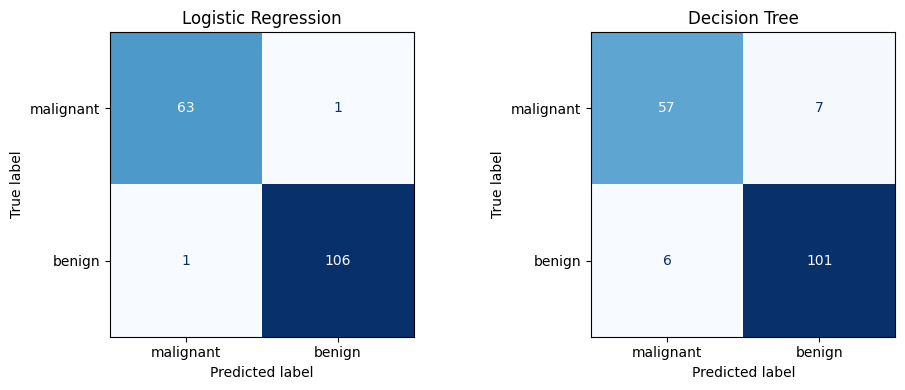

In [8]:
# Visualisasi Confusion Matrix
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (nama, (pred, _)) in zip(ax, hasil.items()):
    ConfusionMatrixDisplay.from_predictions(yb_test, pred,
        display_labels=data.target_names, cmap="Blues", ax=a, colorbar=False)
    a.set_title(nama)
plt.tight_layout(); plt.show()

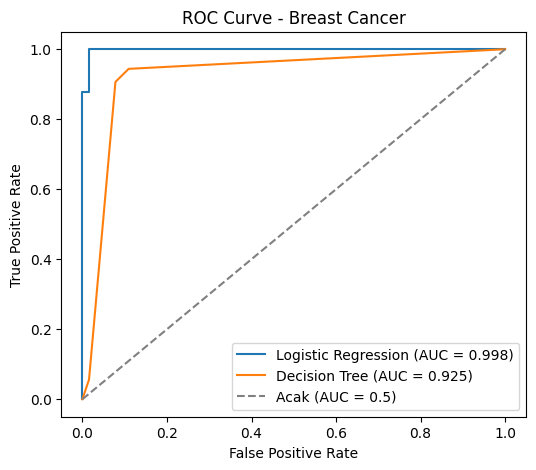

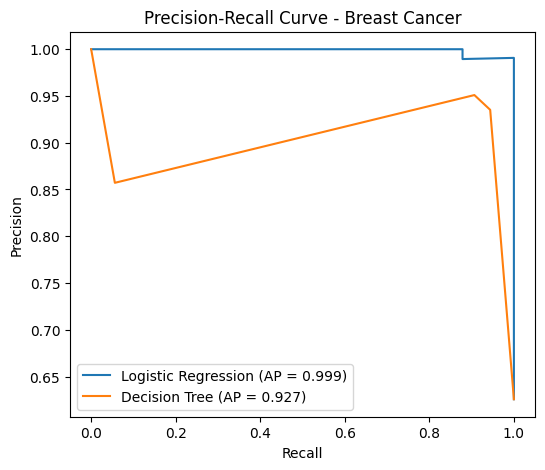

In [9]:
# ROC Curve
plt.figure(figsize=(6, 5))
for nama, (_, proba) in hasil.items():
    fpr, tpr, _ = roc_curve(yb_test, proba)
    plt.plot(fpr, tpr, label=f"{nama} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], '--', color="gray", label="Acak (AUC = 0.5)")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Breast Cancer"); plt.legend(); plt.show()

# Precision-Recall Curve
plt.figure(figsize=(6, 5))
for nama, (_, proba) in hasil.items():
    p, r, _ = precision_recall_curve(yb_test, proba)
    plt.plot(r, p, label=f"{nama} (AP = {average_precision_score(yb_test, proba):.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Breast Cancer"); plt.legend(); plt.show()

In [10]:
# Stratified 5-Fold CV untuk tiap model
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for nama, m in models.items():
    skor = cross_val_score(m, Xb, yb, cv=skf, scoring="f1")
    print(f"{nama:20s} F1 tiap fold: {np.round(skor, 3)}  rata-rata = {skor.mean():.3f} (+/- {skor.std():.3f})")

Logistic Regression  F1 tiap fold: [0.979 0.959 0.973 0.993 0.993]  rata-rata = 0.979 (+/- 0.013)
Decision Tree        F1 tiap fold: [0.965 0.898 0.94  0.943 0.952]  rata-rata = 0.939 (+/- 0.022)


Perbandingan 3 Model dengan Stratified K-Fold CV
Model: Logistic Regression, Decision Tree, dan KNN.

Logistic Regression  F1 = 0.979 (+/- 0.013)
Decision Tree        F1 = 0.939 (+/- 0.022)
KNN                  F1 = 0.971 (+/- 0.014)

Model dengan F1 rata-rata tertinggi: Logistic Regression
Model paling stabil (std terkecil)  : Logistic Regression


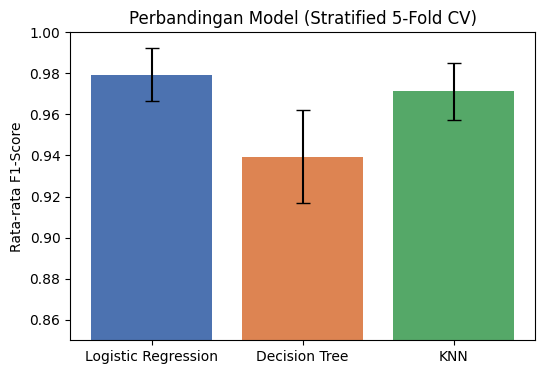

In [11]:
model_list = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
ringkasan = {}
for nama, m in model_list.items():
    skor = cross_val_score(m, Xb, yb, cv=skf, scoring="f1")
    ringkasan[nama] = (skor.mean(), skor.std())
    print(f"{nama:20s} F1 = {skor.mean():.3f} (+/- {skor.std():.3f})")

# Tuliskan kesimpulan model mana yang paling baik dan paling stabil.
terbaik = max(ringkasan, key=lambda k: ringkasan[k][0])
stabil  = min(ringkasan, key=lambda k: ringkasan[k][1])
print("\nModel dengan F1 rata-rata tertinggi:", terbaik)
print("Model paling stabil (std terkecil)  :", stabil)

plt.figure(figsize=(6, 4))
plt.bar(ringkasan.keys(), [v[0] for v in ringkasan.values()],
        yerr=[v[1] for v in ringkasan.values()], capsize=5, color=["#4C72B0", "#DD8452", "#55A868"])
plt.ylim(0.85, 1.0); plt.ylabel("Rata-rata F1-Score")
plt.title("Perbandingan Model (Stratified 5-Fold CV)"); plt.show()